In [1]:
import pandas as pd
import re

CSV_PATH = "nuSeriusBrok.csv"  # pastikan sesuai
df = pd.read_csv(CSV_PATH)
df.head(), df.shape

(                  CommentID             Timestamp               Username  \
 0  UClt56xtfqnLn6zdz6PiYIxg  2025-03-30T13:51:28Z           @AllOfMe2017   
 1  UC8WLbJe15Euo00dUy_zGWag  2025-03-30T15:39:08Z  @rajendraelsyafiq3037   
 2  UCV8BcD2oiX7-NCyLJuNnH6g  2025-03-30T17:14:28Z        @imamsyafii9380   
 3  UCnhBnQaZ7b_Hrilecl6wBzA  2025-03-30T17:26:08Z         @myminifoodies   
 4  UC3DJSQc_7lVCVDFRHjzK3_w  2025-03-30T18:21:05Z     @fuadkurniawan3339   
 
        VideoID   VideoAuthor                        VideoTitle     Subs  \
 0  xk5tzep2zFs  Ridwan Hanif  BYD M6: AVANZANYA MOBIL LISTRIK!  3310000   
 1  xk5tzep2zFs  Ridwan Hanif  BYD M6: AVANZANYA MOBIL LISTRIK!  3310000   
 2  xk5tzep2zFs  Ridwan Hanif  BYD M6: AVANZANYA MOBIL LISTRIK!  3310000   
 3  xk5tzep2zFs  Ridwan Hanif  BYD M6: AVANZANYA MOBIL LISTRIK!  3310000   
 4  xk5tzep2zFs  Ridwan Hanif  BYD M6: AVANZANYA MOBIL LISTRIK!  3310000   
 
                                              Comment  Likes  \
 0  Udah pake 

In [2]:
print(df.columns)

Index(['CommentID', 'Timestamp', 'Username', 'VideoID', 'VideoAuthor',
       'VideoTitle', 'Subs', 'Comment', 'Likes', 'Date'],
      dtype='object')


In [3]:
#OUT_PRE = "youtube_comments_preprocessed.csv"
#df.to_csv(OUT_PRE, index=False, encoding="utf-8-sig")
print(df.shape)

(5521, 10)


## Preprocessing


In [4]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from collections import Counter

nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [5]:
df.info(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5521 entries, 0 to 5520
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CommentID    5521 non-null   object
 1   Timestamp    5521 non-null   object
 2   Username     5521 non-null   object
 3   VideoID      5521 non-null   object
 4   VideoAuthor  5521 non-null   object
 5   VideoTitle   5521 non-null   object
 6   Subs         5521 non-null   int64 
 7   Comment      5521 non-null   object
 8   Likes        5521 non-null   int64 
 9   Date         5521 non-null   object
dtypes: int64(2), object(8)
memory usage: 431.5+ KB


In [6]:
df.head(15)

,CommentID,Timestamp,Username,VideoID,VideoAuthor,VideoTitle,Subs,Comment,Likes,Date
0,UClt56xtfqnLn6zdz6PiYIxg,2025-03-30T13:51:28Z,@AllOfMe2017,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,"Udah pake ini 5 bulan, baru 5000Km,, PR nya me...",309,2025-03-30T13:51:28Z
1,UC8WLbJe15Euo00dUy_zGWag,2025-03-30T15:39:08Z,@rajendraelsyafiq3037,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,harga brp gan ?,4,2025-03-30T15:39:08Z
2,UCV8BcD2oiX7-NCyLJuNnH6g,2025-03-30T17:14:28Z,@imamsyafii9380,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,Kursi driver jongkok ga om . Kliatan g nyaman ...,1,2025-03-30T17:14:28Z
3,UCnhBnQaZ7b_Hrilecl6wBzA,2025-03-30T17:26:08Z,@myminifoodies,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,ban cadangan dmn bang,1,2025-03-30T17:26:08Z
4,UC3DJSQc_7lVCVDFRHjzK3_w,2025-03-30T18:21:05Z,@fuadkurniawan3339,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,@myminifoodies kagak ada. bahkan semua EV demi...,6,2025-03-30T18:21:05Z
5,UClt56xtfqnLn6zdz6PiYIxg,2025-03-30T21:57:27Z,@AllOfMe2017,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,@rajendraelsyafiq3037 otr jateng 434 gan,0,2025-03-30T21:57:27Z
6,UClt56xtfqnLn6zdz6PiYIxg,2025-03-30T22:00:16Z,@AllOfMe2017,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,@imamsyafii9380 kalau posisi duduk di kursi dr...,0,2025-03-30T22:00:16Z
7,UClt56xtfqnLn6zdz6PiYIxg,2025-03-30T22:02:02Z,@AllOfMe2017,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,"@myminifoodies enggak ada bang, wkwkwk, tapi g...",23,2025-03-30T22:02:02Z
8,UCnhBnQaZ7b_Hrilecl6wBzA,2025-03-31T03:40:01Z,@myminifoodies,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,"@AllOfMe2017 gw kebalikannya bang, ni mobil gw...",2,2025-03-31T03:40:01Z
9,UClt56xtfqnLn6zdz6PiYIxg,2025-03-31T03:52:42Z,@AllOfMe2017,xk5tzep2zFs,Ridwan Hanif,BYD M6: AVANZANYA MOBIL LISTRIK!,3310000,"@myminifoodies wah apes kali bang, hahaha",1,2025-03-31T03:52:42Z


In [7]:
#comment section

cekKomen = df.groupby(['VideoID', 'VideoTitle', 'VideoAuthor']).size().reset_index(name='commentCounts').sort_values(by='commentCounts', ascending=False)
cekKomen

,VideoID,VideoTitle,VideoAuthor,commentCounts
1,CHtajideBms,MOBIL KELUARGA TERBAIK? Cuma Nambah Sedikit da...,Carmudi Indonesia,912
3,ISsTDByEnFc,BYD M6 VS TOYOTA INNOVA ZENIX! MANA LEBIH WORT...,OTW Indonesia,828
9,xk5tzep2zFs,BYD M6: AVANZANYA MOBIL LISTRIK!,Ridwan Hanif,807
2,HgwRjhDy54M,🔴 MANTAB PAK‼️INI BARU REVIEW JUJUR PENGGUNA...,CR Underscore Channel,579
4,LKCWQbxm1yA,"Fitur Banyak, Tapi Biasa Saja? Review Jujur BY...",Moladin,512
0,-dyoDGlkm9E,BYD M6 | MPV Listrik Proper Murah Berfaedah,Motomobi,427
5,N1Ril763sxo,Ternyata ini alasan orang pilih BYD M6,AutonetMagz,402
7,iw_e7oQi_Uw,BYD M6 : MPV 7-seater listrik!,AutonetMagz,386
6,OXdRA33vAd4,YAKIN MASIH MAU BELI? INI DIA KEKURANGAN & KEL...,OTW Indonesia,336
8,mjUlIMxRhmc,BYD M6 2024 | Review Indonesia | OtoDriver,Otodriver,332


In [8]:
gakbaku = pd.read_csv('handling kata-kata - nonBaku.csv', header=None, encoding='latin-1')
gakbaku = gakbaku.rename(columns={0: 'original', 1: 'replacement'})
gakbaku.head(10)

mapping_gakbaku = dict(zip(gakbaku['original'], gakbaku['replacement']))

In [9]:
df['Comment'].isna().sum()

np.int64(0)

In [10]:
prep = df['VideoAuthor'].value_counts()
print(prep)

VideoAuthor
OTW Indonesia            1164
Carmudi Indonesia         912
Ridwan Hanif              807
AutonetMagz               788
CR Underscore Channel     579
Moladin                   512
Motomobi                  427
Otodriver                 332
Name: count, dtype: int64


In [13]:
#cek frequent word

cnt = Counter()
for text in df["Comment"].values:
    for word in text.split():
        cnt[word] += 1

cnt.most_common(20)

[('di', 1637),
 ('mobil', 1423),
 ('yg', 1329),
 ('dan', 992),
 ('ada', 788),
 ('nya', 763),
 ('bisa', 704),
 ('itu', 633),
 ('yang', 620),
 ('lebih', 606),
 ('aja', 572),
 ('ini', 568),
 ('ga', 521),
 ('harga', 509),
 ('listrik', 503),
 ('gak', 450),
 ('juga', 430),
 ('dari', 429),
 ('ke', 423),
 ('BYD', 423)]

In [14]:
total_words = sum(cnt.values())

print("Total word frequency:", total_words)

Total word frequency: 100896


In [15]:
!pip install WordCloud

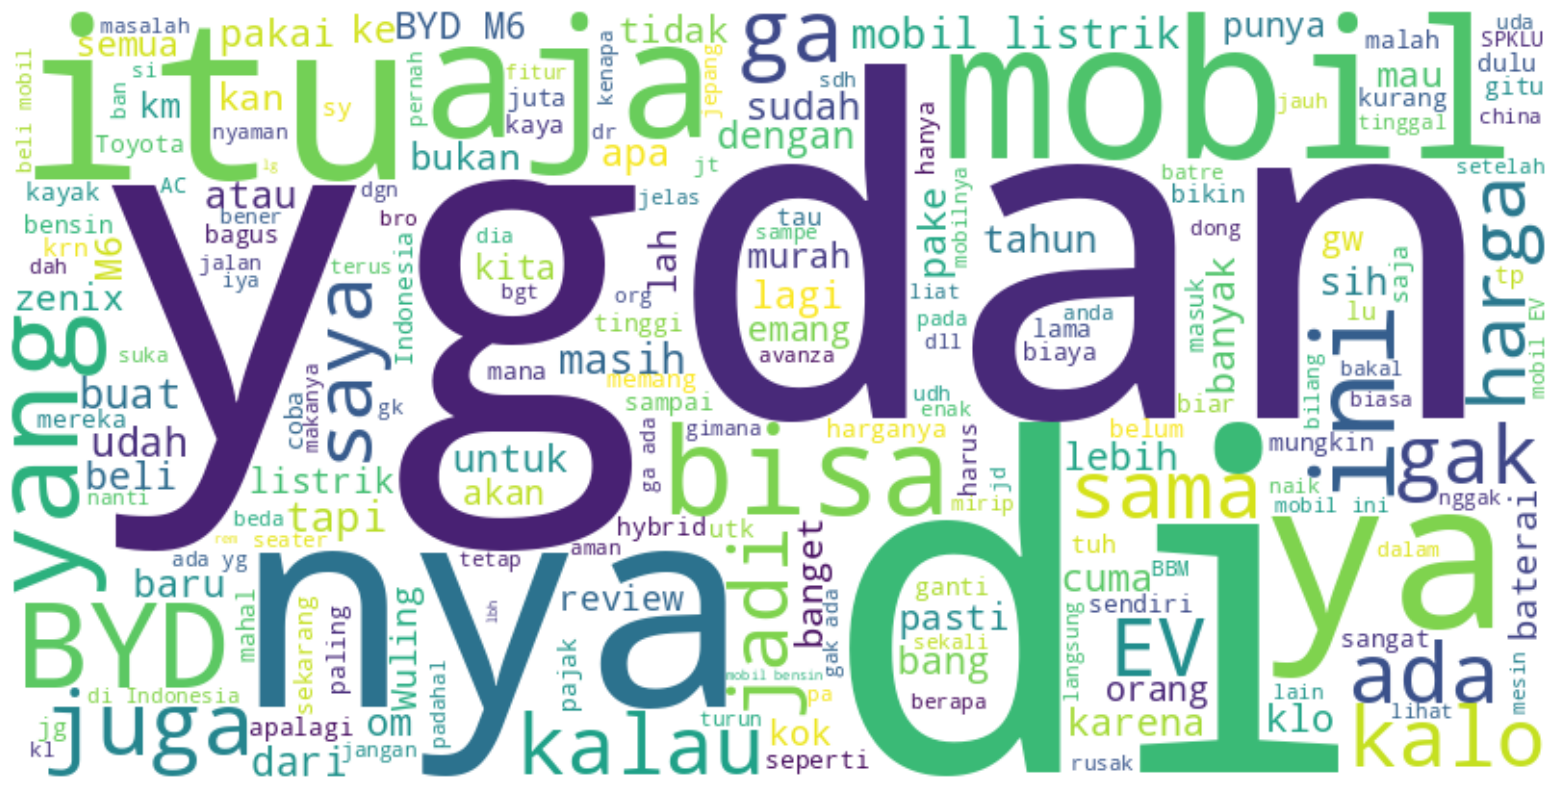

In [19]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Concatenate all comments into a single string
all_comments_text = ' '.join(df['Comment'].astype(str))

# Membuat Word Cloud
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(all_comments_text)

# Tampilkan Word Cloud
plt.figure(figsize=(20, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [20]:
#cek rare word

cnt = Counter()
for text in df["Comment"].values:
    for word in text.split():
        cnt[word] += 1

n_rare_words = 20
cnt.most_common()[:-n_rare_words-1:-1]

[('#micdropped', 1),
 ('box..', 1),
 ('outside', 1),
 ('way...', 1),
 ('will,', 1),
 ('when', 1),
 ('bajay?', 1),
 ('kan.....', 1),
 ('bajay', 1),
 ('supir?', 1),
 ('supir,', 1),
 ('bahaya?', 1),
 ('bisa?', 1),
 ('tuh....', 1),
 ('feet', 1),
 ('ayam,', 1),
 ('ceker', 1),
 ('Kemahalan?', 1),
 ('tali.', 1),
 ('ikat', 1)]

In [21]:
!pip install num2words
!pip install emoji
!pip install Sastrawi

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13781 sha256=fd9c34b4c18440a28d4be90c1775bf1168091df013c69f98ddc3c9627f042d2d
  Stored in directory: /root/.cache/pip/wheels/0b/1d/03/175286677fb5a1341cc3e4755bf8ec0ed08f3329afd67446b0
Successfully built docopt
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [num2words]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 10.4 MB/s  0:00:00


# **Handling Emojis**

In [22]:
def load_emoji_whitelist(filepath: str) -> set:

    whitelist = set()
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            emoji_char = line.split()[0]
            whitelist.add(emoji_char)
    return whitelist

SENTIMENT_EMOJI_WHITELIST = load_emoji_whitelist('sentiment_emoji_whitelist.txt')

In [23]:
import pandas as pd
import re

# ============================================================
# PATTERN DETEKSI EMOJI (broad — untuk filtering df)
# ============================================================

EMOJI_DETECT_PATTERN = re.compile(
    "["
                               u"\U0001F600-\U0001F64F"  # emoticons
                               u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                               u"\U0001F680-\U0001F6FF"  # transport & map symbols
                               u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                               u"\U00002500-\U00002BEF"  # chinese char
                               u"\U00002702-\U000027B0"
                               u"\U00002702-\U000027B0"
                               u"\U000024C2-\U0001F251"
                               u"\U0001f926-\U0001f937"
                               u"\U00010000-\U0010ffff"
                               u"\u2640-\u2642"
                               u"\u2600-\u2B55"
                               u"\u200d"
                               u"\u23cf"
                               u"\u23e9"
                               u"\u231a"
                               u"\ufe0f"  # dingbats
                               u"\u3030"
                               "]+", flags=re.UNICODE
)

def has_emoji(text: str) -> bool:
    if not isinstance(text, str):
        return False
    return bool(EMOJI_DETECT_PATTERN.search(text))

# Skenario 1: filter dasar — semua baris yang ada emoji apapun
df_has_emoji = df[df['Comment'].apply(has_emoji)]


# Skenario 2: filter hanya yang mengandung emoji SENTIMEN (dari whitelist)
SENTIMENT_EMOJI_WHITELIST = load_emoji_whitelist('sentiment_emoji_whitelist.txt')

def has_sentiment_emoji(text: str, whitelist: set) -> bool:
    if not isinstance(text, str):
        return False
    return any(char in whitelist for char in text)

df_sentiment_emoji = df[
    df['Comment'].apply(lambda x: has_sentiment_emoji(x, SENTIMENT_EMOJI_WHITELIST))
]


# Skenario 3: tambah kolom flag — lebih fleksibel untuk analisis lanjutan
df['has_emoji']           = df['Comment'].apply(has_emoji)
df['has_sentiment_emoji'] = df['Comment'].apply(
    lambda x: has_sentiment_emoji(x, SENTIMENT_EMOJI_WHITELIST)
)
df['has_noise_emoji_only'] = df['has_emoji'] & ~df['has_sentiment_emoji']

# lalu filter sesuai kebutuhan
df_for_validation = df[df['has_sentiment_emoji']]


# ============================================================
# BONUS: ringkasan distribusi untuk validasi
# ============================================================

print("=== EMOJI DISTRIBUTION SUMMARY ===")
print(f"Total komentar          : {len(df)}")
print(f"Mengandung emoji apapun : {df['has_emoji'].sum()}")
print(f"Emoji sentimen          : {df['has_sentiment_emoji'].sum()}")
print(f"Emoji noise saja        : {df['has_noise_emoji_only'].sum()}")
print(f"Tanpa emoji sama sekali : {(~df['has_emoji']).sum()}")

=== EMOJI DISTRIBUTION SUMMARY ===
Total komentar          : 5521
Mengandung emoji apapun : 1288
Emoji sentimen          : 95
Emoji noise saja        : 1193
Tanpa emoji sama sekali : 4233


In [24]:
import re

def build_emoji_pattern_excluding_whitelist(whitelist: set) -> re.Pattern:

    full_emoji_pattern = re.compile(
        "["
                               u"\U0001F600-\U0001F64F"  # emoticons
                               u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                               u"\U0001F680-\U0001F6FF"  # transport & map symbols
                               u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                               u"\U00002500-\U00002BEF"  # chinese char
                               u"\U00002702-\U000027B0"
                               u"\U00002702-\U000027B0"
                               u"\U000024C2-\U0001F251"
                               u"\U0001f926-\U0001f937"
                               u"\U00010000-\U0010ffff"
                               u"\u2640-\u2642"
                               u"\u2600-\u2B55"
                               u"\u200d"
                               u"\u23cf"
                               u"\u23e9"
                               u"\u231a"
                               u"\ufe0f"  # dingbats
                               u"\u3030"
                               "]+", flags=re.UNICODE
    )

    def selective_replace(match):
        token = match.group(0)
        # Jika token adalah emoji yang ada di whitelist → pertahankan
        if any(char in whitelist for char in token):
            return token
        # Sisanya → hapus
        return ''

    return full_emoji_pattern, selective_replace

def remove_emoji_keep_sentiment(text: str) -> str:

    pattern, replacer = build_emoji_pattern_excluding_whitelist(
        SENTIMENT_EMOJI_WHITELIST
    )
    return pattern.sub(replacer, text)

def load_emoji_whitelist(filepath: str) -> dict:
    whitelist      = set()
    emoji_to_token = {}

    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue

            parts = line.split(maxsplit=4)
            if len(parts) < 3:
                continue

            emoji_char, _, kategori = parts[:3]

            whitelist.add(emoji_char)
            # Token langsung dari kolom kategori → "positif" / "negatif"
            emoji_to_token[emoji_char] = kategori.lower()

    return {
        'whitelist'     : whitelist,
        'emoji_to_token': emoji_to_token
    }

def replace_sentiment_emoji_with_token(text: str, emoji_to_token: dict) -> str:
    for emoji_char, token in emoji_to_token.items():
        text = text.replace(emoji_char, f' {token} ')
    return text

# Corrected line to sample actual comment strings
samples = df_for_validation['Comment'].sample(5)

# Load the emoji_to_token mapping using the load_emoji_whitelist defined in this cell
sentiment_emoji_data_local = load_emoji_whitelist('sentiment_emoji_whitelist.txt')
emoji_to_token_map = sentiment_emoji_data_local['emoji_to_token']

df['Comment'] = df['Comment'].apply(lambda x: replace_sentiment_emoji_with_token(x, emoji_to_token_map))

print("=" * 60)
for s in samples:
    cleaned = remove_emoji_keep_sentiment(str(s)) # Ensure 's' is a string
    tokenized = replace_sentiment_emoji_with_token(cleaned, emoji_to_token_map) # Pass the emoji_to_token_map
    print(f"ORIGINAL  : {s}")
    print(f"CLEANED   : {cleaned}")
    print(f"TOKENIZED : {tokenized}")
    print("-" * 60)

ORIGINAL  : Mobil mssa depan , nanti pada waktunya akan beralih ke listrik semuanya 👍,,ramah lingkungan ,dan penghematan
CLEANED   : Mobil mssa depan , nanti pada waktunya akan beralih ke listrik semuanya 👍,,ramah lingkungan ,dan penghematan
TOKENIZED : Mobil mssa depan , nanti pada waktunya akan beralih ke listrik semuanya  positif ,,ramah lingkungan ,dan penghematan
------------------------------------------------------------
ORIGINAL  : Terbaik memang byd m6 🔥🔥🔥
CLEANED   : Terbaik memang byd m6 🔥🔥🔥
TOKENIZED : Terbaik memang byd m6  positif  positif  positif 
------------------------------------------------------------
ORIGINAL  : Bgs itu, dan jgn tanggung2, subsidi listrik ama listrik diskon malem2 jg cabut.. Biar adil sekalian. Klo udah semua, baru ngomong lg lu.. 😂😂
Dan mudah2an jg jd ngurangin org gob*og di jalan 👍
CLEANED   : Bgs itu, dan jgn tanggung2, subsidi listrik ama listrik diskon malem2 jg cabut.. Biar adil sekalian. Klo udah semua, baru ngomong lg lu.. 
Dan mudah2an j

# **Preprocessing**

In [25]:
import re
import string
from num2words import num2words
import emoji
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory, StopWordRemover, ArrayDictionary
from nltk.tokenize import word_tokenize

factory = StopWordRemoverFactory()
stopword = factory.create_stop_word_remover()
#text preprocessing

def remove_emoji(string):
    emoji_pattern = re.compile("["
                               u"\U0001F600-\U0001F64F"  # emoticons
                               u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                               u"\U0001F680-\U0001F6FF"  # transport & map symbols
                               u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                               u"\U00002500-\U00002BEF"  # chinese char
                               u"\U00002702-\U000027B0"
                               u"\U00002702-\U000027B0"
                               u"\U000024C2-\U0001F251"
                               u"\U0001f926-\U0001f937"
                               u"\U00010000-\U0010ffff"
                               u"\u2640-\u2642"
                               u"\u2600-\u2B55"
                               u"\u200d"
                               u"\u23cf"
                               u"\u23e9"
                               u"\u231a"
                               u"\ufe0f"  # dingbats
                               u"\u3030"
                               "]+", flags=re.UNICODE)
    return emoji_pattern.sub(r' ', string)

def lowercasing(text):
  return text.lower()

def remove_mentions(text):
    return re.sub(r'@[\w.\-]+', '', text)

def remove_timestamp_format(text):
    return re.sub(r'\b\d{1,2}:\d{2}\b', '', text)

def normalize_repetition(text):
    text = re.sub(r'(\w+)2\b', r'\1-\1', text)
    return text

def remove_repeated_chars(text):
    return re.sub(r'([a-zA-Z])\1{2,}', r'\1', text)

def remove_punctuation(text):
    text = re.sub(r'(?<!\w)-{1}(?!\w)', ' ', text)
    text = re.sub(r'[^\w\s]+', ' ', text)  # replace semua tanda baca jadi spasi
    text = re.sub(r'\s+', ' ', text)        # rapiin spasi ganda
    text = text.strip()
    return text

def normalize_price(text):
    text = re.sub(r'\b(\d+)\s+jt\b', r'\1juta', text)
    text = re.sub(r'\b(\d+)\s+juta\b', r'\1juta', text)
    text = re.sub(r'\b(\d+)\s+ribu\b', r'\1ribu', text)
    return text

def remove_html_tags(text):
    # Regex untuk mencocokkan tag HTML
    html_tag_pattern = r'<[^>]+>'
    return re.sub(html_tag_pattern, '', text)

def remove_urls(text):
    # Regex untuk mencocokkan URL
    url_pattern = r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+'
    text = re.sub(url_pattern, '', text)
    # Hapus tag HTML setelah menghapus URL
    text = remove_html_tags(text)
    return text

def remove_double_whitespace(text):
    return re.sub(r'\s+', ' ', text).strip()

# ========== define preprocessing ============

def cleansing(text):
    text = remove_emoji(text)
    text = lowercasing(text)
    text = remove_mentions(text)
    text = remove_timestamp_format(text)
    text = normalize_repetition(text)
    text = remove_repeated_chars(text)
    text = remove_punctuation(text)
    text = normalize_price(text)
    text = remove_html_tags(text)
    text = remove_urls(text)
    text = remove_double_whitespace(text)

    return text

df['PreposText'] = df['Comment'].apply(lambda text: cleansing(text))

In [26]:
df['PreposText'].head(20)

,PreposText
0,udah pake ini 5 bulan baru 5000km pr nya meman...
1,harga brp gan
2,kursi driver jongkok ga om kliatan g nyaman gitu
3,ban cadangan dmn bang
4,kagak ada bahkan semua ev demikin pula tobyatt
5,otr jateng 434 gan
6,kalau posisi duduk di kursi driver sih enggak ...
7,enggak ada bang wkwkwk tapi gimana juga ya ant...
8,gw kebalikannya bang ni mobil gw aja udah 4x k...
9,wah apes kali bang hahaha


# **tokenizing**

In [27]:
import nltk
nltk.download('punkt_tab')

def tokenize(text):
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if len(t) > 1]

    seen = set()
    unique_tokens = []
    for t in tokens:
        if t not in seen:
            seen.add(t)
            unique_tokens.append(t)

    return unique_tokens

df['tokenizerText'] = df['PreposText'].apply(tokenize)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [28]:
df['tokenizerText'].head(20)

,tokenizerText
0,"[udah, pake, ini, bulan, baru, 5000km, pr, nya..."
1,"[harga, brp, gan]"
2,"[kursi, driver, jongkok, ga, om, kliatan, nyam..."
3,"[ban, cadangan, dmn, bang]"
4,"[kagak, ada, bahkan, semua, ev, demikin, pula,..."
5,"[otr, jateng, 434, gan]"
6,"[kalau, posisi, duduk, di, kursi, driver, sih,..."
7,"[enggak, ada, bang, wkwkwk, tapi, gimana, juga..."
8,"[gw, kebalikannya, bang, ni, mobil, aja, udah,..."
9,"[wah, apes, kali, bang, hahaha]"


# **stemming**

In [29]:
!pip install --upgrade git+https://github.com/ariaghora/mpstemmer.git
!pip install python-Levenshtein git+https://github.com/ariaghora/mpstemmer.git

  Cloning https://github.com/ariaghora/mpstemmer.git to /tmp/pip-req-build-f978qsmg
  Running command git clone --filter=blob:none --quiet https://github.com/ariaghora/mpstemmer.git /tmp/pip-req-build-f978qsmg
  Resolved https://github.com/ariaghora/mpstemmer.git to commit 25a5fd923af163a7eac3a5ec976984156ca8fa8b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for mpstemmer: filename=mpstemmer-0.1.0-py3-none-any.whl size=99831 sha256=ca9ab1a6cb04631c870082a6c88e79ae7f62b11a2f51acbb69195c125c21bc4e
  Stored in directory: /tmp/pip-ephem-wheel-cache-5pozisdm/wheels/d0/b9/fd/dba0c7d44e5338db51da6ffcbe96db4326db3996a403f5ced1
Successfully built mpstemmer
  Cloning https://github.com/ariaghora/mpstemmer.git to /tmp/pip-req-build-ozx0tru3
  Running command git clone --filter=blob:none --quiet https://github.com/ariaghora/mpstemmer.git /tmp/pip-req-build-ozx0tru3
  Resolved https://github.com

In [30]:
from mpstemmer import MPStemmer
import Levenshtein

stemmer = MPStemmer()

df['stemmed'] = df['tokenizerText'].apply(
   lambda tokens: [stemmer.stem(word) for word in tokens]
)

def STEMnya(word):
    if isinstance(word, str) and word.endswith('nya') and len(word) > 4:
        return word[:-3]
    return word

def ngeSTEMin(word):
    if isinstance(word, str) and word.startswith('nge') and word.endswith('in') and len(word) > 6:
        return word[3:-2] # Corrected slicing from word[3:: -2]
    return word

def ngSTEMin(word):
    if isinstance(word, str) and word.startswith('ng') and word.endswith('in') and len(word) > 6:
        return word[2:-2] # Corrected slicing from word[2:: -2]
    return word

def diSTEMin(word):
    if isinstance(word, str) and word.startswith('di') and word.endswith('in') and len(word) > 5:
        return word[2:-2] # Corrected slicing from word[2:: -2]
    return word

def keSTEMan(word):
    if isinstance(word, str) and word.startswith('ke') and word.endswith('an') and len(word) > 5:
        return word[2:-2] # Corrected slicing from word[2:: -2]
    return word

def slangStem(word):
    # Ensure word is a string before processing
    if not isinstance(word, str):
        return word

    temp_word = STEMnya(word)
    temp_word = ngeSTEMin(temp_word)
    temp_word = ngSTEMin(temp_word)
    temp_word = diSTEMin(temp_word)
    temp_word = keSTEMan(temp_word)
    return temp_word

df['stemmed'] = df['stemmed'].apply(lambda tokens: [slangStem(word) for word in tokens])

In [31]:
df['stemmed'].head(20)

,stemmed
0,"[udah, pake, ini, bulan, baru, 5000km, pr, nya..."
1,"[harga, brp, gan]"
2,"[kursi, driver, jongkok, tidak, om, kliatan, n..."
3,"[ban, cadang, dmn, bang]"
4,"[kagak, ada, bahkan, semua, ev, demik, pula, t..."
5,"[otr, jateng, 434, gan]"
6,"[kalau, posisi, duduk, di, kursi, driver, sih,..."
7,"[tidak, ada, bang, wkwkwk, tapi, gimana, juga,..."
8,"[gue, balik, bang, ini, mobil, aja, udah, 4x, ..."
9,"[wah, apes, kali, bang, hahaha]"


# **normalize gakbaku**

In [32]:
# Baca whitelist dari CSV
import pandas as pd

df_whitelist = pd.read_csv('handling kata-kata - Whitelist.csv')
whitelistDict = set(df_whitelist['Whitelist'].str.strip().str.lower().tolist())
# sesuaikan 'word' dengan nama kolom di CSV kamu

# NLTK stopwords
nltk.download('stopwords')
nltk_stopwords = set(stopwords.words('indonesian'))

# Sastrawi stopwords
factory = StopWordRemoverFactory()
default_stopwords = factory.get_stop_words()
more_stopword = ['mas', 'nya', 'ya', 'banget', 'bang', 'sih', 'om', 'kak']
all_stopwords = default_stopwords + more_stopword

# Gabungin semua stopwords, lalu buang yang ada di whitelist
effective_stopwords = (set(all_stopwords) | nltk_stopwords) - whitelistDict  # ← whitelist dikeluarin dari semua

def normalize_gakbaku(word_list):
    return [mapping_gakbaku[word] if word in mapping_gakbaku else word for word in word_list]

def custom_stopwords(word_list):
    return [
        word for word in word_list
        if word.lower() not in effective_stopwords or word.lower() in whitelistDict
    ]

def preprocess(tokens_list):
    tokens = normalize_gakbaku(tokens_list)   # 1. normalize
    tokens = custom_stopwords(tokens)          # 2. remove stopwords (sudah include whitelist)
    return tokens

df['FinalNormalizer'] = df['stemmed'].apply(preprocess)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [33]:
df['FinalNormalizer'].head(20)

,FinalNormalizer
0,"[pakai, 5000km, pr, visibilitas, lumayan, bant..."
1,"[harga, teman]"
2,"[kursi, driver, jongkok, tidak, kliatan, nyaman]"
3,"[ban, cadang]"
4,"[tidak, ada, mobil listrik, demik, tobyatt]"
5,"[otr, jateng, 434, teman]"
6,"[posisi, duduk, kursi, driver, tidak, ada, com..."
7,"[tidak, ada, tawa, iya, tidak, 10, pakai, mobi..."
8,"[mobil, 4x, kena, paku, belum, taun, kwkwkwkwk]"
9,"[apes, kali, tawa]"


# **Stopwords Removal**

In [34]:
comparizon = df[['Comment', 'PreposText', 'tokenizerText', 'stemmed', 'FinalNormalizer']]

In [35]:
comparizon.head(30)

,Comment,PreposText,tokenizerText,stemmed,FinalNormalizer
0,"Udah pake ini 5 bulan, baru 5000Km,, PR nya me...",udah pake ini 5 bulan baru 5000km pr nya meman...,"[udah, pake, ini, bulan, baru, 5000km, pr, nya...","[udah, pake, ini, bulan, baru, 5000km, pr, nya...","[pakai, 5000km, pr, visibilitas, lumayan, bant..."
1,harga brp gan ?,harga brp gan,"[harga, brp, gan]","[harga, brp, gan]","[harga, teman]"
2,Kursi driver jongkok ga om . Kliatan g nyaman ...,kursi driver jongkok ga om kliatan g nyaman gitu,"[kursi, driver, jongkok, ga, om, kliatan, nyam...","[kursi, driver, jongkok, tidak, om, kliatan, n...","[kursi, driver, jongkok, tidak, kliatan, nyaman]"
3,ban cadangan dmn bang,ban cadangan dmn bang,"[ban, cadangan, dmn, bang]","[ban, cadang, dmn, bang]","[ban, cadang]"
4,@myminifoodies kagak ada. bahkan semua EV demi...,kagak ada bahkan semua ev demikin pula tobyatt,"[kagak, ada, bahkan, semua, ev, demikin, pula,...","[kagak, ada, bahkan, semua, ev, demik, pula, t...","[tidak, ada, mobil listrik, demik, tobyatt]"
5,@rajendraelsyafiq3037 otr jateng 434 gan,otr jateng 434 gan,"[otr, jateng, 434, gan]","[otr, jateng, 434, gan]","[otr, jateng, 434, teman]"
6,@imamsyafii9380 kalau posisi duduk di kursi dr...,kalau posisi duduk di kursi driver sih enggak ...,"[kalau, posisi, duduk, di, kursi, driver, sih,...","[kalau, posisi, duduk, di, kursi, driver, sih,...","[posisi, duduk, kursi, driver, tidak, ada, com..."
7,"@myminifoodies enggak ada bang, wkwkwk, tapi g...",enggak ada bang wkwkwk tapi gimana juga ya ant...,"[enggak, ada, bang, wkwkwk, tapi, gimana, juga...","[tidak, ada, bang, wkwkwk, tapi, gimana, juga,...","[tidak, ada, tawa, iya, tidak, 10, pakai, mobi..."
8,"@AllOfMe2017 gw kebalikannya bang, ni mobil gw...",gw kebalikannya bang ni mobil gw aja udah 4x k...,"[gw, kebalikannya, bang, ni, mobil, aja, udah,...","[gue, balik, bang, ini, mobil, aja, udah, 4x, ...","[mobil, 4x, kena, paku, belum, taun, kwkwkwkwk]"
9,"@myminifoodies wah apes kali bang, hahaha",wah apes kali bang hahaha,"[wah, apes, kali, bang, hahaha]","[wah, apes, kali, bang, hahaha]","[apes, kali, tawa]"


In [36]:
comparizon.to_excel('YOSHIYOSHIIIIII.xlsx', index=False)

## ngecek aje

In [37]:
#cek frequent word

cnt = Counter()
for text in comparizon["FinalNormalizer"].values:
    for word in text:
        cnt[word] += 1

cnt.most_common(20)

[('tidak', 1515),
 ('mobil', 1318),
 ('ada', 784),
 ('bisa', 692),
 ('iya', 674),
 ('pakai', 642),
 ('harga', 638),
 ('lebih', 624),
 ('byd', 624),
 ('listrik', 504),
 ('m6', 478),
 ('baterai', 443),
 ('beli', 437),
 ('mobil listrik', 430),
 ('sangat', 420),
 ('banyak', 392),
 ('belum', 311),
 ('orang', 275),
 ('bagus', 271),
 ('jual', 269)]

In [38]:
#cek rare word

cnt = Counter()
for text in comparizon["FinalNormalizer"].values:
    for word in text:
        cnt[word] += 1

n_rare_words = 20
cnt.most_common()[:-n_rare_words-1:-1]

[('micdropped', 1),
 ('outside', 1),
 ('way', 1),
 ('when', 1),
 ('bajay', 1),
 ('feet', 1),
 ('ayam', 1),
 ('ceker', 1),
 ('ikat', 1),
 ('stylus', 1),
 ('pen', 1),
 ('eyerolled', 1),
 ('m0xxn', 1),
 ('b3g0', 1),
 ('omg', 1),
 ('phew', 1),
 ('helps', 1),
 ('hope', 1),
 ('temp', 1),
 ('finger', 1)]

In [39]:
all_words = [word for tokens in comparizon["FinalNormalizer"] for word in tokens]
common_words = pd.Series(all_words).value_counts()

# Menampilkan 20 kata yang paling umum
print(common_words)

tidak     1515
mobil     1318
ada        784
bisa       692
iya        674
          ... 
totot        1
getohh       1
m0xxn        1
b3g0         1
omg          1
Name: count, Length: 8204, dtype: int64


In [40]:
total_words = sum(cnt.values())

print("Total word frequency:", total_words)

Total word frequency: 56173


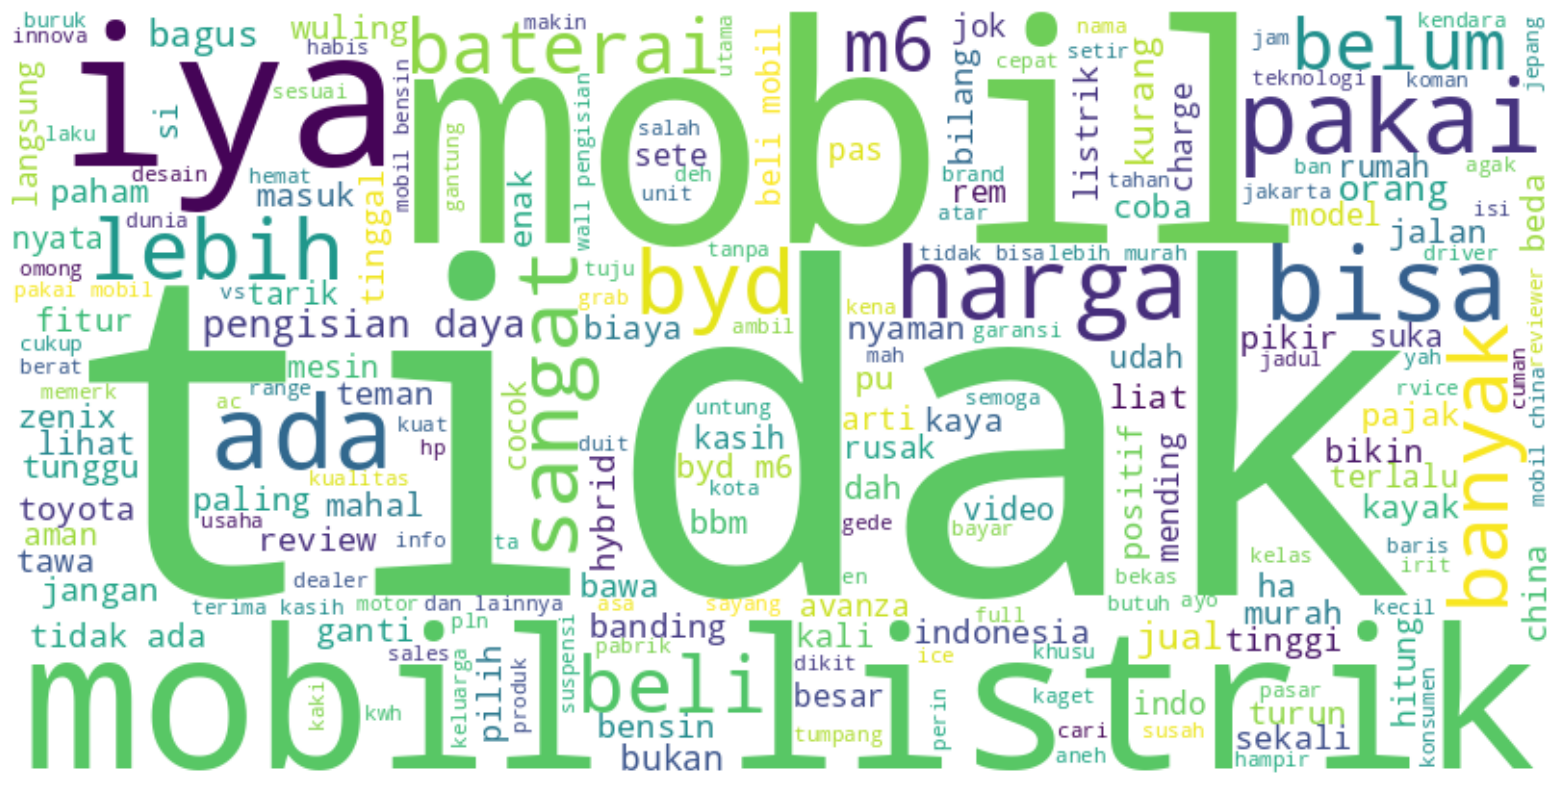

In [41]:
import matplotlib.pyplot as plt

all_text = ' '.join(all_words)

# Membuat Word Cloud
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(all_text)

# Tampilkan Word Cloud
plt.figure(figsize=(20, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [42]:
common_words.reset_index().rename(columns={'index': 'kata', 'count': 'frekuensi'}).to_excel('labellingLagi.xlsx', index=False)

In [43]:
.

SyntaxError: invalid syntax (1933637684.py, line 1)

# **Labelling with Indo Lexicon**

In [ ]:
import pandas as pd

# main corpus

# Load kamus berbobot
kamus_pos = pd.read_csv('tambahan_positif.csv')
kamus_neg = pd.read_csv('tambahan_negatif.csv')

# Gabungin jadi satu dict
kamus_bobot = {}
kamus_bobot.update(dict(zip(kamus_pos['kata'], kamus_pos['bobot'])))
kamus_bobot.update(dict(zip(kamus_neg['kata'], kamus_neg['bobot'])))

# Whitelist negasi & penegas
negasi = {"tidak", "bukan", "jangan", "belum", "tanpa", "enggak", "kurang"}
penegas = {"lebih", "sangat", "semakin", "teramat", "beneran"}

def label_sentiment(tokens):
    score = 0

    for i, word in enumerate(tokens):
        if word in kamus_bobot:
            prev_word = tokens[i-1] if i > 0 else None

            is_negated  = prev_word in negasi   # "tidak bagus" → balik bobot
            is_emphasis = prev_word in penegas  # "semakin bagus" → tambah +1/-1

            bobot = kamus_bobot[word]

            if is_negated:
                score += -bobot             # balik arah bobotnya
            elif is_emphasis:
                score += bobot + (1 if bobot > 0 else -1)  # tambah +1 atau -1 sesuai arah
            else:
                score += bobot              # bobot normal

    if score > 0:
        return "positif"
    elif score < 0:
        return "negatif"
    else:
        return "netral"

# Apply ke FinalNormalizer
df['label'] = df['FinalNormalizer'].apply(label_sentiment)

# Cek hasil
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True) * 100)

# Preview sample per kelas
for sentimen in ['positif', 'negatif', 'netral']:
    print(f"\n=== Sample {sentimen} ===")
    sample = df[df['label'] == sentimen][['Comment', 'FinalNormalizer', 'label']].sample(3)
    print(sample)

In [ ]:
print(len(kamus_bobot))

In [ ]:
step1 = kamus_bobot.copy()
print(len(step1))

In [ ]:
.

In [ ]:
import pandas as pd

# addition corpus

# Load kamus berbobot utama
kamus_pos = pd.read_csv('tambahan_positif.csv')
kamus_neg = pd.read_csv('tambahan_negatif.csv')

# Load support data (tanpa bobot)
# Fixed: Load without header and assign 'kata' as column name
support_pos = pd.read_csv('positive.csv', header=None, names=['kata'])
support_neg = pd.read_csv('negative.csv', header=None, names=['kata'])

# Gabungin kamus utama dulu
kamus_bobot = {}
kamus_bobot.update(dict(zip(kamus_pos['kata'], kamus_pos['bobot'])))
kamus_bobot.update(dict(zip(kamus_neg['kata'], kamus_neg['bobot'])))

# Tambah support data — skip kalau udah ada di kamus utama
support_pos_list = support_pos['kata'].tolist()
support_neg_list = support_neg['kata'].tolist()

for word in support_pos_list:
    if word not in kamus_bobot:  # skip kalau udah ada
        kamus_bobot[word] = 3   # default +3

for word in support_neg_list:
    if word not in kamus_bobot:  # skip kalau udah ada
        kamus_bobot[word] = -3  # default -3

print(f"Total kamus setelah merge: {len(kamus_bobot)} kata")

# Cek berapa yang di-skip vs ditambah
skipped_pos = [w for w in support_pos_list if w in kamus_bobot and kamus_bobot[w] != 3]
added_pos = [w for w in support_pos_list if kamus_bobot.get(w) == 3]
skipped_neg = [w for w in support_neg_list if w in kamus_bobot and kamus_bobot[w] != -3]
added_neg = [w for w in support_neg_list if kamus_bobot.get(w) == -3]

print(f"Support positif → ditambah: {len(added_pos)}, di-skip: {len(skipped_pos)}")
print(f"Support negatif → ditambah: {len(added_neg)}, di-skip: {len(skipped_neg)}")

In [ ]:
print(len(kamus_bobot))

In [ ]:
step2 = kamus_bobot.copy()
print(len(step2))

In [ ]:
.

In [ ]:
import pandas as pd

# Load support data (tanpa bobot)
# Fixed: Load without header and assign 'kata' as column name
support_pos_third = pd.read_csv('lexiconPositive.csv', header=None, names=['kata'])
support_neg_third = pd.read_csv('lexiconNegative.csv', header=None, names=['kata'])

# Gabungin kamus utama dulu
kamus_bobot = {}
kamus_bobot.update(dict(zip(kamus_pos['kata'], kamus_pos['bobot'])))
kamus_bobot.update(dict(zip(kamus_neg['kata'], kamus_neg['bobot'])))

# Tambah support data — skip kalau udah ada di kamus utama
support_pos_list_third = support_pos_third['kata'].tolist()
support_neg_list_third = support_neg_third['kata'].tolist()


print(f"Total kamus setelah merge: {len(kamus_bobot)} kata")

# Cek berapa yang di-skip vs ditambah
skipped_pos_third = [w for w in support_pos_list_third if w in kamus_bobot]
added_pos_third = [w for w in support_pos_list_third if w not in kamus_bobot]
skipped_neg_third = [w for w in support_neg_list_third if w in kamus_bobot]
added_neg_third = [w for w in support_neg_list_third if w not in kamus_bobot]

print(f"Support positif → ditambah: {len(added_pos)}, di-skip: {len(skipped_pos)}")
print(f"Support negatif → ditambah: {len(added_neg)}, di-skip: {len(skipped_neg)}")

In [ ]:
.

In [ ]:
# Load support data BARU yang udah ada bobot built-in
support_pos = pd.read_csv('lexiconPositive.csv')  # kolom: kata, bobot
support_neg = pd.read_csv('lexiconNegative.csv')  # kolom: kata, bobot

# Gabungin kamus utama dulu
kamus_bobot = {}
kamus_bobot.update(dict(zip(kamus_pos['kata'], kamus_pos['bobot'])))
kamus_bobot.update(dict(zip(kamus_neg['kata'], kamus_neg['bobot'])))

print(f"Kamus utama: {len(kamus_bobot)} kata")

updated   = []  # kata yang bobotnya di-update ke bobot kamus utama
kept      = []  # kata baru yang langsung pakai bobot built-in
conflict_pos_to_neg = []  # kata di support positif tapi bobot jadi negatif setelah update
conflict_neg_to_pos = []  # kata di support negatif tapi bobot jadi positif setelah update

# Proses support positif
support_pos_dict = dict(zip(support_pos['kata'], support_pos['bobot']))
for word, builtin_bobot in support_pos_dict.items():
    if word in kamus_bobot:
        # Kata udah ada → update ke bobot kamus utama
        final_bobot = kamus_bobot[word]  # pakai bobot kamus utama
        updated.append({
            'kata': word,
            'bobot_builtin': builtin_bobot,
            'bobot_final': final_bobot
        })
        # Cek silang: apakah bobot kamus utama malah jadi negatif?
        if final_bobot < 0:
            conflict_pos_to_neg.append({
                'kata': word,
                'bobot_builtin': builtin_bobot,
                'bobot_final': final_bobot
            })
    else:
        # Kata baru → pakai bobot built-in
        kamus_bobot[word] = builtin_bobot
        kept.append({'kata': word, 'bobot': builtin_bobot})

# ================================================================
# Summary
# ================================================================
print(f"\nTotal kamus setelah merge : {len(kamus_bobot)} kata")
print(f"Kata di-update bobotnya   : {len(updated)}")
print(f"Kata baru (bobot built-in): {len(kept)}")

print(f"\n⚠️  Konflik pos→neg : {len(conflict_pos_to_neg)} kata")
for c in conflict_pos_to_neg:
    print(f"   '{c['kata']}': built-in {c['bobot_builtin']} → final {c['bobot_final']}")

# ================================================================
# Export hasil konflik untuk direview manual
# ================================================================
if conflict_pos_to_neg or conflict_neg_to_pos:
    df_konflik = pd.DataFrame(
        conflict_pos_to_neg + conflict_neg_to_pos
    )
    df_konflik['arah_konflik'] = (
        ['pos→neg'] * len(conflict_pos_to_neg) +
        ['neg→pos'] * len(conflict_neg_to_pos)
    )
    df_konflik.to_csv('konflik_bobot.csv', index=False)
    print(f"\nKonflik disimpan ke konflik_bobot.csv untuk direview manual")

In [ ]:
# kamus_bobot udah berisi main corpus + additional corpus (4001 kata)
# langsung apply aja

df['label'] = df['FinalNormalizer'].apply(label_sentiment)

# Cek hasil
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True) * 100)

In [ ]:
print(df['label'].value_counts(normalize=True) * 100)

In [ ]:
#pukimay.to_excel("aturBang.xlsx", index=False)

In [ ]:
.

# **coverage netral**

In [ ]:
df_netral = df[df['label'] == 'netral'][['Comment', 'FinalNormalizer']].sample(20)
print(df_netral)

In [ ]:
df_netral.to_excel("semuaAja.xlsx", index=False)

In [ ]:
# Berapa % token yang ke-cover kamus?

# Initialize pos_words and neg_words from kamus_bobot
# kamus_bobot is assumed to be available from cell OclRbwiUtjOQ
pos_words = {word for word, score in kamus_bobot.items() if score > 0}
neg_words = {word for word, score in kamus_bobot.items() if score < 0}

def coverage(tokens):
    covered = [w for w in tokens if w in pos_words or w in neg_words]
    return len(covered) / len(tokens) if tokens else 0

df['kamus_coverage'] = df['FinalNormalizer'].apply(coverage)
print(f"Rata-rata coverage: {df['kamus_coverage'].mean():.2%}")
print(f"Coverage = 0 (ga ada yg match): {(df['kamus_coverage'] == 0).sum()} baris")

In [ ]:
from collections import Counter

# Kumpulin semua token yang belum di kamus
uncovered = []
for tokens in df['FinalNormalizer']:
    for w in tokens:
        if w not in pos_words and w not in neg_words:
            uncovered.append(w)

# Hitung semua frekuensi (tanpa limit)
uncovered_counter = Counter(uncovered)

# Export ke txt (format: kata\tfrekuensi, urut dari terbanyak)
with open('uncovered_words.txt', 'w', encoding='utf-8') as f:
    for word, freq in uncovered_counter.most_common():  # tanpa argumen = semua
        f.write(f"{word}\t{freq}\n")

print(f"Total kata uncovered: {len(uncovered_counter)}")
print(f"Berhasil disimpan ke uncovered_words.txt")

# **rebalancing netral**

In [ ]:
pd.DataFrame(top_uncovered, columns=['kata', 'frekuensi']).to_csv('gaspolDangak.txt', sep='\t', index=False)

# **TF-IDF**

In [ ]:
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Gabungin final_text dulu
df['final_text'] = df['FinalNormalizer'].apply(lambda x: ' '.join(x))

# TF-IDF
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(df['final_text'])

X = tfidf_matrix
y = df['label']

# Cek distribusi kelas
print(y.value_counts())

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape[0]} data")
print(f"Test  : {X_test.shape[0]} data")

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(X_train, y_train)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = nb.predict(X_test)

# Classification report
print(classification_report(y_test, y_pred, target_names=['negatif', 'netral', 'positif']))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['positif', 'negatif', 'netral'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['positif', 'negatif', 'netral'])

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

In [ ]:
# option 1
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import numpy as np

params_alpha = {'alpha': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]}

grid_alpha = GridSearchCV(
    ComplementNB(),
    params_alpha,
    cv=5,
    scoring='f1_macro',
    verbose=1
)
grid_alpha.fit(X_train, y_train)

print(f"[Option 1] Best alpha : {grid_alpha.best_params_}")
print(f"[Option 1] Best score : {grid_alpha.best_score_:.4f}")

In [ ]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', ComplementNB())
])

pipeline_params = {
    'tfidf__ngram_range'  : [(1,1), (1,2), (1,3)],
    'tfidf__min_df'       : [1, 2, 3],
    'tfidf__sublinear_tf' : [True, False],
    'tfidf__max_df'       : [0.90, 0.95, 1.0],
    'clf__alpha'          : [0.01, 0.1, 0.5, 1.0, 2.0],
}

grid_pipeline = GridSearchCV(
    pipeline,
    pipeline_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,      # pakai semua core
    verbose=1
)

# Fit langsung pakai data string (bukan matrix)
grid_pipeline.fit(df.loc[y_train.index, 'final_text'], y_train)

print(f"\n[Option 3] Best params : {grid_pipeline.best_params_}")
print(f"[Option 3] Best score  : {grid_pipeline.best_score_:.4f}")

# **tuning parameter**

# **ngetes doa ibu**

In [ ]:
def predict_sentiment(text):
    # 1. Apply initial cleansing (string -> string)
    # This includes remove_mentions, remove_repeated_chars, etc., as defined in the `cleansing` function.
    cleaned_text_step1 = cleansing(text)

    # 2. Tokenization (string -> list of strings)
    tokens_step2 = tokenize(cleaned_text_step1)

    # 3. Stemming (list of strings -> list of strings)
    # First, apply MPStemmer (stemmer is globally available)
    stemmed_tokens_step3 = [stemmer.stem(t) for t in tokens_step2]
    # Then, apply custom slangStem transformations (slangStem is globally available)
    stemmed_tokens_step3_slang = [slangStem(t) for t in stemmed_tokens_step3]

    # 4. Final normalization and stopword removal using the `preprocess` function
    # The `preprocess` function (from cell QP4TTFp03ryV) already contains the `normalize_gakbaku` (for list of words)
    # and `custom_stopwords` steps, ensuring correct data type handling.
    final_processed_tokens = preprocess(stemmed_tokens_step3_slang)

    # 5. Join tokens into a single string for TF-IDF vectorization
    final_text = ' '.join(final_processed_tokens)
    print(f"Setelah preprocessing : {final_text}")

    # 6. Transform using the fitted TF-IDF vectorizer
    # `tfidf` and `nb` are assumed to be globally available from previous executed cells.
    vec = tfidf.transform([final_text])

    # 7. Predict sentiment
    pred = nb.predict(vec)[0]
    proba = nb.predict_proba(vec)[0]

    print(f"\nTeks asli  : {text}")
    print(f"Sentimen   : {pred}")
    print(f"\nProbabilitas:")
    for label, prob in zip(nb.classes_, proba):
        print(f"  {label:10s}: {prob:.4f} ({prob*100:.1f}%)")

    return pred

# Test pakai komentar kamu sendiri
predict_sentiment("hemat")
predict_sentiment("nyaman")
predict_sentiment("kecewa sama pelayanannya, ga recommended")

In [ ]:
import pickle

# Simpan semua komponen yang dibutuhkan
model_components = {
    'kamus_bobot'   : kamus_bobot,
    'negasi'        : negasi,
    'penegas'       : penegas,
    'tfidf'         : tfidf,
    'nb'            : nb,
}

# Save pickle
with open('sentiment_model.pkl', 'wb') as f:
    pickle.dump(model_components, f)

print("Model berhasil disimpan ke sentiment_model.pkl")

# Load pickle
with open('sentiment_model.pkl', 'rb') as f:
    loaded = pickle.load(f)

# Ekstrak komponen
kamus_bobot = loaded['kamus_bobot']
negasi      = loaded['negasi']
penegas     = loaded['penegas']
tfidf       = loaded['tfidf']
nb          = loaded['nb']

print("Model berhasil di-load!")
print(f"Total kamus  : {len(kamus_bobot)} kata")
print(f"Total negasi : {len(negasi)} kata")
print(f"Total penegas: {len(penegas)} kata")

# **iyah**

In [ ]:
.

In [ ]:
all_words = [word for tokens in comparizon["FinalNormalizer"] for word in tokens]
common_words = pd.Series(all_words).value_counts()
common_words

In [ ]:
#common_words.reset_index().rename(columns={'index': 'kata', 'count': 'frekuensi'}).to_excel('KAREPE_KOEN.xlsx', index=False)

In [ ]:
from google.colab import auth
import gspread
from google.auth import default
import pandas as pd

auth.authenticate_user()
creds, _ = default()

gc = gspread.authorize(creds)

spreadsheet_id = "1Bx8X0GItl7EoFzmS6kBYRuA5atdhLDifkloPOJG7-0E"
sh = gc.open_by_key(spreadsheet_id)
wargaPositif = sh.worksheet("posetep")
wargaNegatep = sh.worksheet("negatep")

excel1 = wargaPositif.get_all_records()
excel2 = wargaNegatep.get_all_records()
rulebasedDF = pd.DataFrame(excel1)
rulebasedDF2 = pd.DataFrame(excel2)

rule_based = pd.concat([rulebasedDF, rulebasedDF2], ignore_index=True)

In [ ]:
rule_based

In [ ]:
import re

def label_sentiment(text):
    text_lower = text.lower()

    pos_words = rulebasedDF[rulebasedDF['sentimen'] == 'positif']['kata'].tolist()
    neg_words = rulebasedDF2[rulebasedDF2['sentimen'] == 'negatif']['kata'].tolist()

    pos_score = sum(1 for word in pos_words if word in text_lower)
    neg_score = sum(1 for word in neg_words if word in text_lower)

    if pos_score > neg_score:
        return "positif"
    elif neg_score > pos_score:
        return "negatif"
    else:
        return "netral"

In [ ]:
prepFinal['label'] = prepFinal['Comment'].apply(label_sentiment)
print(prepFinal['label'].value_counts())

In [ ]:
checker = prepFinal[['Date','Comment', 'label']]
checker

In [ ]:
checker.to_excel("skripsiGathelPol.xlsx", index=False)